# K-means 2 — chemical profiles in real wine measurements

**Question:** can numerical measurements organize wines into useful descriptive groups?
The UCI Wine dataset has 178 observations and 13 chemical features, with known cultivar
labels reserved for a final audit. It is a small real dataset, not a production study.

Run cells in order. scikit-learn bundles the dataset: no download or external CSV is needed.
We fit all rows for descriptive exploration and make no held-out classification claim.
You will inspect scaling, choose K without cultivar labels, describe centroids in original
units, visualize a 2D projection, and check partition stability.

## 1. Imports and the data contract
`load_wine(as_frame=True).data` contains only numerical features. The target is deliberately not loaded into the analysis until the audit section. Every row is one wine sample.

In [1]:
from pathlib import Path
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

SEED = 23
COLORS = ["#147d92", "#e49b32", "#8b62a9", "#db6b59", "#3d9570", "#6b7494", "#ad6680", "#747c37"]
from matplotlib.colors import ListedColormap
CMAP = ListedColormap(COLORS)
plt.rcParams.update({"figure.dpi": 115, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 12})
ROOT = Path.cwd()
if (ROOT / "KMeans").is_dir():
    ROOT = ROOT / "KMeans"
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)
(ROOT / ".build").mkdir(exist_ok=True)

def save_figure(fig, name):
    fig.savefig(FIGURES / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIGURES / f"{name}.png", dpi=160, bbox_inches="tight")

print(f"Python {platform.python_version()} | scikit-learn {sklearn.__version__}")

Python 3.12.9 | scikit-learn 1.8.0


In [2]:
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
X = load_wine(as_frame=True).data.copy()
assert X.shape == (178, 13)
assert "target" not in X.columns and np.isfinite(X.to_numpy()).all()
print("Rows, features:", X.shape)
print("Missing entries:", int(X.isna().sum().sum()))
display(X.head())
display(X.agg(["mean", "std", "min", "max"]).T.round(3))

Rows, features: (178, 13)
Missing entries: 0


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


,mean,std,min,max
alcohol,13.001,0.812,11.03,14.83
malic_acid,2.336,1.117,0.74,5.80
ash,2.367,0.274,1.36,3.23
alcalinity_of_ash,19.495,3.340,10.60,30.00
magnesium,99.742,14.282,70.00,162.00
total_phenols,2.295,0.626,0.98,3.88
flavanoids,2.029,0.999,0.34,5.08
nonflavanoid_phenols,0.362,0.124,0.13,0.66
proanthocyanins,1.591,0.572,0.41,3.58
color_intensity,5.058,2.318,1.28,13.00


## 2. Make the distance choice explicit

A difference of 100 in `proline` contributes 10,000 to raw squared distance;
a difference of 1 in `alcohol` contributes 1. These numerical scales do not
establish chemical importance. We choose equal per-feature variance weighting:
$z_{ij}=(x_{ij}-\bar x_j)/s_j$, using `StandardScaler`'s population SD.

Standardization is a modeling assumption. Correlated measurements can still
receive repeated weight, and outliers can influence both the scaler and means.
No missing values require imputation in this dataset.

In [3]:
scaler = StandardScaler().fit(X)
Z = scaler.transform(X)
np.testing.assert_allclose(Z.mean(axis=0), 0, atol=1e-12)
np.testing.assert_allclose(Z.std(axis=0), 1, atol=1e-12)
print("Standardized shape:", Z.shape)

Standardized shape: (178, 13)


## 3. Choose K without cultivar labels
Evaluate K=1,...,8 in the standardized 13-dimensional space. Choose the highest silhouette among K=2,...,8, with smaller K winning ties. Inspect both curves; this bounded search is an exploratory convention, not proof of a unique natural grouping.

,inertia,silhouette
K,,
1,2314.0000,NaN
2,1658.7589,0.2593
3,1277.9285,0.2849
4,1175.7052,0.2517
5,1113.9038,0.2017
6,1045.2777,0.2410
7,993.3245,0.2007
8,934.4849,0.1495


Selected K: 3


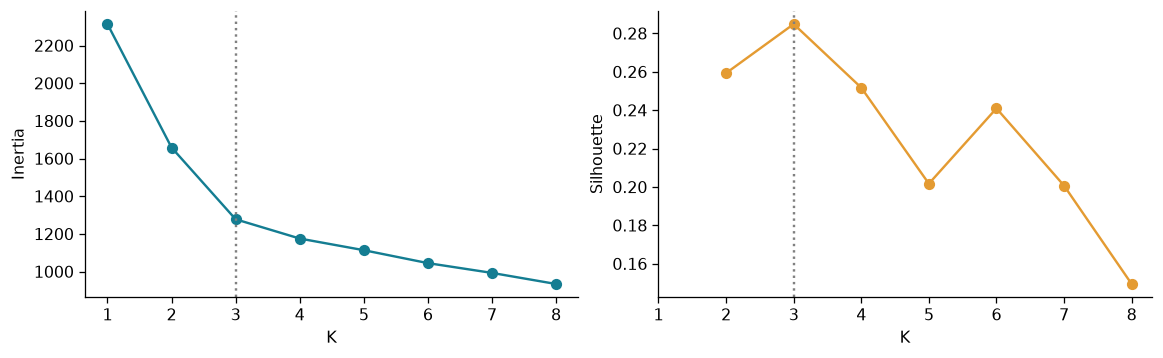

In [4]:
models = {}
rows = []
for k in range(1, 9):
    fitted = KMeans(n_clusters=k, init="k-means++", n_init=20,
                    random_state=SEED).fit(Z)
    models[k] = fitted
    rows.append({"K": k, "inertia": fitted.inertia_,
                 "silhouette": silhouette_score(Z, fitted.labels_) if k > 1 else np.nan})
scores = pd.DataFrame(rows).set_index("K")
selected_k = int(scores.silhouette.idxmax())
model = models[selected_k]
labels = model.labels_
display(scores.round(4))
print("Selected K:", selected_k)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.0), constrained_layout=True)
for ax, column, color in zip(axes, ["inertia", "silhouette"], COLORS):
    ax.plot(scores.index, scores[column], "o-", color=color)
    ax.axvline(selected_k, color="0.5", ls=":")
    ax.set(xlabel="K", ylabel=column.capitalize(), xticks=scores.index)
save_figure(fig, "wine_selection")
plt.show()

## 4. Describe groups rather than naming classes

`cluster_centers_` are standardized profiles. Apply the fitted scaler's
`inverse_transform` to recover the original measurement units.
The resulting centers should equal group means of the original rows.
The heatmap shows deviations from the overall feature mean in SD units;
cluster numbers are arbitrary, so describe their profiles rather than attach cultivar names.

,n,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
cluster,,,,,,,,,,,,,,
0,65,12.25,1.90,2.23,20.06,92.74,2.25,2.05,0.36,1.62,2.97,1.06,2.80,510.17
1,62,13.68,2.00,2.47,17.46,107.97,2.85,3.00,0.29,1.92,5.45,1.07,3.16,1100.23
2,51,13.13,3.31,2.42,21.24,98.67,1.68,0.82,0.45,1.15,7.23,0.69,1.70,619.06


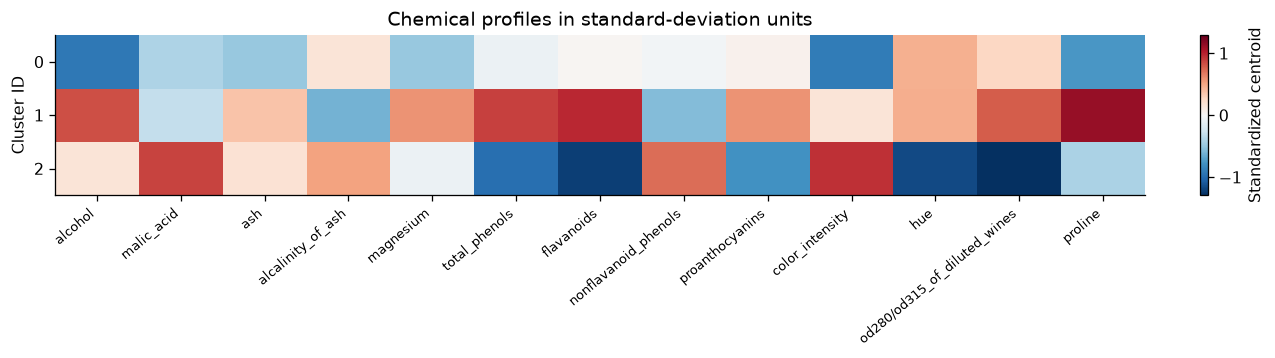

In [5]:
centers_original = pd.DataFrame(scaler.inverse_transform(model.cluster_centers_),
                                columns=X.columns)
centers_original.index.name = "cluster"
profiles = centers_original.copy()
profiles.insert(0, "n", np.bincount(labels, minlength=selected_k))
display(profiles.round(2))
observed_means = X.assign(cluster=labels).groupby("cluster").mean()
np.testing.assert_allclose(centers_original, observed_means, rtol=1e-10)
fig, ax = plt.subplots(figsize=(11, 3), constrained_layout=True)
limit = float(np.abs(model.cluster_centers_).max())
im = ax.imshow(model.cluster_centers_, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")
ax.set(xticks=range(X.shape[1]), xticklabels=X.columns,
       yticks=range(selected_k), ylabel="Cluster ID", title="Chemical profiles in standard-deviation units")
plt.setp(ax.get_xticklabels(), rotation=40, ha="right", fontsize=8)
fig.colorbar(im, ax=ax, label="Standardized centroid")
save_figure(fig, "wine_profiles")
plt.show()

## 5. Visualize, while keeping the full fitting space

PCA finds two directions of high variance for a plot. K-means was fitted
on **all 13 standardized features**, not on these two coordinates.
Project the fitted centers through the same PCA. Apparent overlap or distance
in this picture can omit structure from the remaining components.

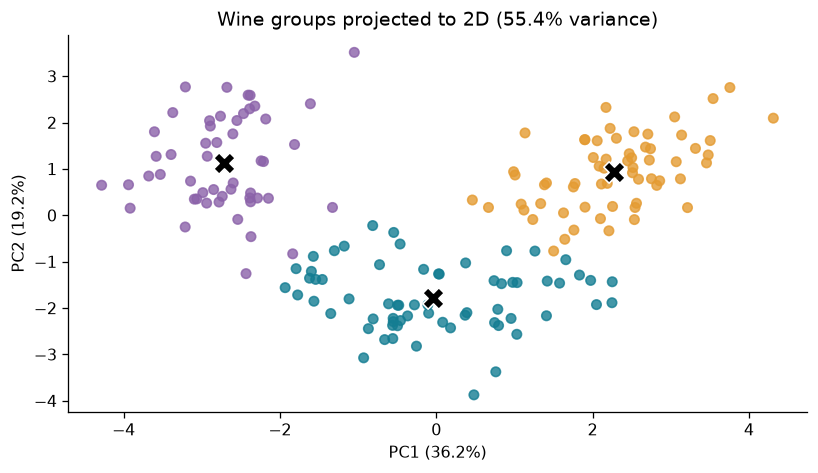

In [6]:
pca = PCA(n_components=2, svd_solver="full").fit(Z)
projected = pca.transform(Z)
projected_centers = pca.transform(model.cluster_centers_)
explained = float(pca.explained_variance_ratio_.sum())
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
ax.scatter(*projected.T, c=labels, cmap=CMAP, vmin=0, vmax=7, s=35, alpha=0.8)
ax.scatter(*projected_centers.T, marker="X", s=180, c="black", edgecolors="white")
ax.set(xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.1%})",
       ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.1%})",
       title=f"Wine groups projected to 2D ({explained:.1%} variance)")
save_figure(fig, "wine_projection")
plt.show()

## 6. Audit using the cultivar labels, after freezing the analysis

The known cultivars did not determine scaling or K. Now inspect the contingency
table and ARI. Never compute ordinary accuracy by comparing cultivar integers
with arbitrary cluster IDs. Also compare raw-feature clustering at the same K:
this is a sensitivity audit, not a label-driven replacement of the chosen model.
Inertias under different scalings have different units and cannot be ranked directly.

In [7]:
cultivar_for_audit = load_wine().target
audit_table = pd.crosstab(pd.Series(cultivar_for_audit, name="cultivar code"),
                         pd.Series(labels, name="cluster"))
display(audit_table)
wine_ari = adjusted_rand_score(cultivar_for_audit, labels)
raw_model = KMeans(n_clusters=selected_k, n_init=20, random_state=SEED).fit(X)
raw_ari = adjusted_rand_score(cultivar_for_audit, raw_model.labels_)
print(f"Scaled audit ARI: {wine_ari:.3f}; raw audit ARI: {raw_ari:.3f}")
print(f"Raw/scaled partition agreement: {adjusted_rand_score(raw_model.labels_, labels):.3f}")

cluster,0,1,2
cultivar code,,,
0,0,59,0
1,65,3,3
2,0,0,48


Scaled audit ARI: 0.897; raw audit ARI: 0.371
Raw/scaled partition agreement: 0.354


## 7. Check sensitivity to resampling

Fix the selected K. Refit both the scaler and K-means on 20 independently drawn
80% subsamples, and predict group assignments for all original rows.
Compare each assignment with the full-data partition using ARI.
This tests reproducibility of the descriptive grouping; the scores include
fitting rows and are not held-out accuracy estimates. Stability alone cannot
establish scientific meaning or robustness to other populations.

In [8]:
stability_rows = []
for seed in range(20):
    rng = np.random.default_rng(seed)
    subset = rng.choice(len(X), size=int(0.8 * len(X)), replace=False)
    refit = make_pipeline(StandardScaler(), KMeans(n_clusters=selected_k,
                          n_init=20, random_state=seed)).fit(X.iloc[subset])
    stability_rows.append({"seed": seed,
        "ARI_to_full_fit": adjusted_rand_score(labels, refit.predict(X))})
stability = pd.DataFrame(stability_rows)
display(stability.describe().loc[["mean", "std", "min", "max"], ["ARI_to_full_fit"]].round(3))
summary = {"selected_k": selected_k, "inertia": float(model.inertia_),
           "silhouette": float(scores.loc[selected_k, "silhouette"]),
           "ari": float(wine_ari), "raw_ari": float(raw_ari),
           "pca_variance": explained,
           "sizes": np.bincount(labels).tolist(),
           "stability_mean": float(stability.ARI_to_full_fit.mean()),
           "stability_min": float(stability.ARI_to_full_fit.min())}
(ROOT / ".build" / "wine_metrics.json").write_text(json.dumps(summary, indent=2) + "\n")

,ARI_to_full_fit
mean,0.990
std,0.017
min,0.947
max,1.000


310

## 8. Assign a future row using the fitted preprocessing

Apply `scaler.transform` followed by `model.predict`, without refitting either.
For this API demonstration we copy an existing row; it is **not new evaluation data**.
A real new row must have the same 13 features, column order, and measurement units.
Assignment gives a descriptive group, not a cultivar probability.

In [9]:
example_row = X.iloc[[0]].copy()
example_z = scaler.transform(example_row)
group = int(model.predict(example_z)[0])
nearest = float(model.transform(example_z).min())
print({"assigned_cluster": group, "nearest_center_distance": round(nearest, 3)})
assert group == int(labels[0])

{'assigned_cluster': 1, 'nearest_center_distance': 2.063}


## 9. Try it yourself

1. List the three strongest positive or negative standardized deviations for each
   centroid. Explain the chemical profiles without using cultivar labels.
2. Drop `proline`, refit the scaler and the selected number of centers, and report
   agreement with the original full-feature partition. Does one omitted feature
   change the grouping? Do not reselect the model using cultivar ARI.

In [10]:
# Reference solution 1: retain the sign while sorting by absolute deviation.
for cluster, center in enumerate(model.cluster_centers_):
    deviations = pd.Series(center, index=X.columns)
    strongest = deviations.loc[deviations.abs().nlargest(3).index]
    print(f"Cluster {cluster}:", strongest.round(2).to_dict())

# Reference solution 2: compare partitions, not the numeric cluster IDs.
reduced = X.drop(columns="proline")
reduced_pipeline = make_pipeline(StandardScaler(), KMeans(n_clusters=selected_k,
                                 n_init=20, random_state=SEED)).fit(reduced)
print("ARI after dropping proline:", round(adjusted_rand_score(
      labels, reduced_pipeline.predict(reduced)), 3))

Cluster 0: {'alcohol': -0.93, 'color_intensity': -0.9, 'proline': -0.75}
Cluster 1: {'proline': 1.13, 'flavanoids': 0.98, 'total_phenols': 0.89}
Cluster 2: {'od280/od315_of_diluted_wines': -1.29, 'flavanoids': -1.22, 'hue': -1.16}
ARI after dropping proline: 0.896


## Dataset credit

Aeberhard, S. & Forina, M. (1992). **Wine** [Dataset]. UCI Machine Learning Repository.
[DOI: 10.24432/C5PC7J](https://doi.org/10.24432/C5PC7J).
[CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
We use the scikit-learn packaged copy with standardized feature names and zero-based
cultivar codes; standardization and PCA are analysis transformations.
See [UCI dataset information](https://archive.ics.uci.edu/dataset/109/wine) and
[load_wine documentation](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_wine.html).

## Sources and attribution

The companion reading is GeeksforGeeks, [K means Clustering – Introduction](https://www.geeksforgeeks.org/machine-learning/k-means-clustering-introduction/)
(accessed 27 October 2026). Its two borrowed figures appear, with credits, in `k_means_clustering.pdf`.
The code, numerical experiments, and plots here were written for this teaching supplement.

Technical references: scikit-learn [KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html),
[silhouette](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html),
[adjusted Rand index](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html).
See [ATTRIBUTION.md](ATTRIBUTION.md) for all image URLs and dataset credits.